In [1]:
%pylab inline
import stmpy
import stmpy.driftcorr as dfc
import h5py

pylab.style.use('Thin')

Populating the interactive namespace from numpy and matplotlib


In [2]:
# data = f['reconstruction']
# en = f['energies']

def convert_fft(f):
    data = f['reconstruction']
    en = f['energies']
    data_real = data['real']
    data_img = data['imag']
    ft_real = fft.fftshift(data_real[0])
    ft_img = fft.fftshift(data_img[0])
    ft_amp = sqrt(ft_real**2+ft_img**2)
    real_map = real(fft.ifft2(data_real[0]+1j * data_img[0]))
    return en, ft_amp, real_map

# Conventional 40 nm DOS map

In [46]:
# d1 = stmpy.load("conventional 40 nm BSSCO map.spy")
d1 = stmpy.load("Grid Spectroscopy-BSCCO-2022-09-04-002.3ds", biasOffset=False)

File import successful.


In [83]:
d2 = stmpy.load('data/2022-09-05-BSCCO-SparseSamplingDOS-002.3ds')

File import successful.
Corrected for a bias offset of -1.51 meV


In [84]:
shape(d2.LIY)

(12, 1, 36100)

In [48]:
d1.header

{'Grid dim': '"250 x 250"',
 'Grid settings': '-5.040688E-8;-5.187596E-8;4.000000E-8;4.000000E-8;2.572162E+1',
 'Filetype': 'Linear',
 'Sweep Signal': '"Bias (V)"',
 'Fixed parameters': '"Sweep Start;Sweep End"',
 'Experiment parameters': '"X (m);Y (m);Z (m);Z offset (m);Settling time (s);Integration time (s);Z-Ctrl hold;Final Z (m);Scan:Current (A);Scan:Z (m)"',
 '# Parameters (4 byte)': '12',
 'Experiment size (bytes)': '192',
 'Points': '12',
 'Channels': '"Current (A);Bias (V);LI Demod 1 X (A);LI Demod 1 Y (A)"',
 'Delay before measuring (s)': '10.000000E-3',
 'Experiment': '"Grid Spectroscopy"',
 'Start time': '"04.09.2022 23:41:48"',
 'End time': '"05.09.2022 14:26:00"',
 'User': '',
 'Comment': '"BSCCO, 100mV/70pA,  2.5 mV excit, 22 mV to -22 mv with 12 pts, 40x40 nm with 250x250 pts"',
 'Bias>Bias (V)': '100E-3',
 'Bias>Calibration (V/V)': '1E+0',
 'Bias>Offset (V)': '-1.4E-3',
 'Bias Spectroscopy>Sweep Start (V)': '22E-3',
 'Bias Spectroscopy>Sweep End (V)': '-22E-3',
 'Bias S

In [18]:
d2.en

array([ 0.0235096,  0.0195096,  0.0155096,  0.0115096,  0.0075096,
        0.0035096, -0.0004904, -0.0044904, -0.0084904, -0.0124904,
       -0.0164904, -0.0204904])

In [19]:
d2.LIY[0].shape
layer1 = d2.LIY[-1][0]
shape(layer1)
savetxt('testing_map2.txt', layer1)

In [11]:
t1 = loadtxt('data/mask1.txt')

In [12]:
len(t1)

15625

In [17]:
d1.z = stmpy.tools.lineSubtract(d1.Z, 2)

## Drift corrrect the conventional map

The coordinates of the Bragg peaks are:
array([[207,  60],
       [ 43, 190],
       [ 66,  51],
       [184, 199]])

The coordinates of the Q vectors are:
array([[ 83, -64],
       [-81,  66],
       [-58, -73],
       [ 60,  75]])


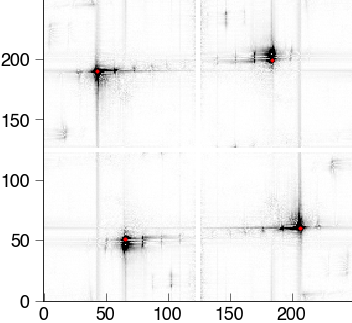

In [18]:
liy_topo = copy(d1.z)
bp1 = dfc.findBraggs(liy_topo, min_dist=10, r=0.2, w=0.01, show=True)

(-0.5, 249.5, -0.5, 249.5)

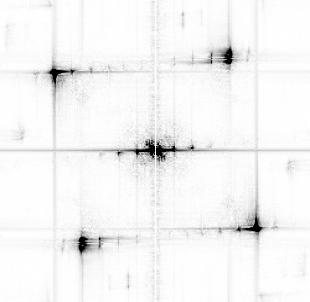

In [30]:
z_fft = stmpy.tools.fft(liy_topo, zeroDC=True)
c = mean(z_fft)
s = std(z_fft)
figure()
imshow(z_fft, cmap=stmpy.cm.gray_r, clim=[0, c+5*s])
axis('off')

In [19]:
bp_c = dfc.generate_bp(liy_topo, bp=bp1, orient=arctan2(-64, 83), even_out=True)
bp_c

array([[ 64,  46],
       [ 46, 184],
       [184, 202],
       [202,  64]])

The coordinates of the Bragg peaks are:
array([[207,  60],
       [ 43, 190],
       [ 66,  51],
       [184, 199]])

The coordinates of the Q vectors are:
array([[ 83, -64],
       [-81,  66],
       [-58, -73],
       [ 60,  75]])


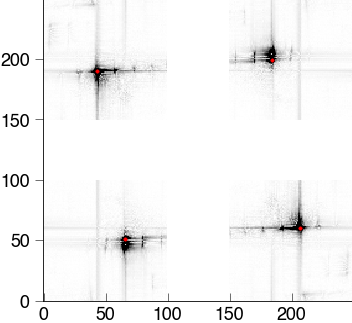

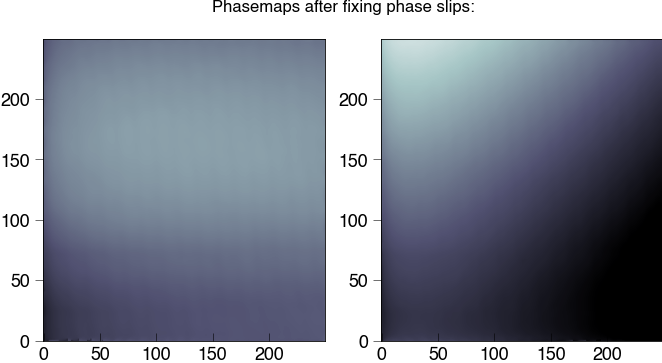

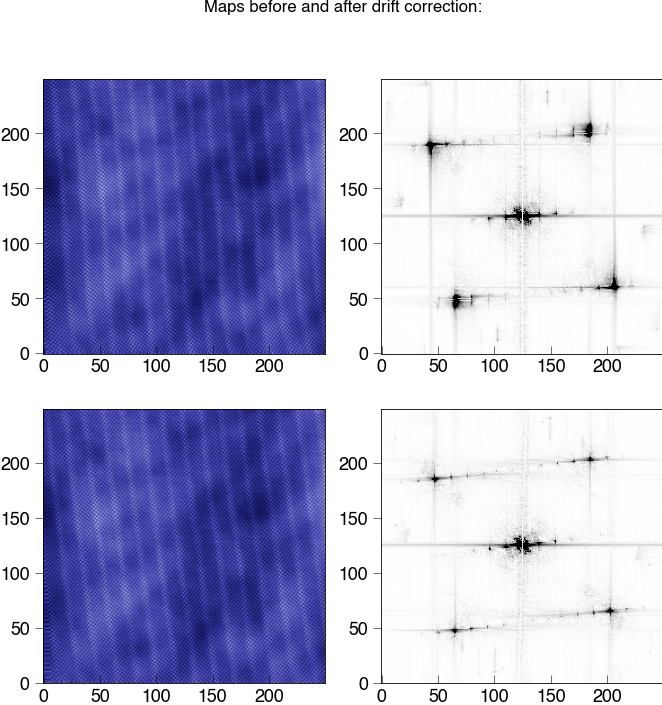

In [21]:
z_c1, param1 = dfc.find_drift_parameter(liy_topo, r=0.2, w=0.1, min_dist=10, bp_c=bp_c, #cut2=5, 
                                      sigma=20, method='lockin')

The coordinates of the Bragg peaks are:
array([[203,  65],
       [ 47, 185],
       [ 65,  47],
       [185, 203]])

The coordinates of the Q vectors are:
array([[ 79, -59],
       [-77,  61],
       [-59, -77],
       [ 61,  79]])


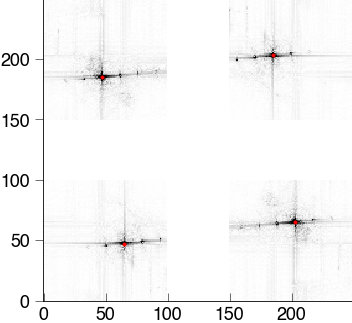

In [22]:
bp2 = dfc.findBraggs(z_c1, rspace=True, r=0.2, w=0.1, min_dist=20, show=True)

In [23]:
bp_c2 = dfc.generate_bp(z_c1, bp=bp2, orient=arctan2(-59, 79), even_out=True)
bp_c2

array([[ 66,  46],
       [ 46, 182],
       [182, 202],
       [202,  66]])

The coordinates of the Bragg peaks are:
array([[203,  65],
       [ 47, 185],
       [ 65,  47],
       [185, 203]])

The coordinates of the Q vectors are:
array([[ 79, -59],
       [-77,  61],
       [-59, -77],
       [ 61,  79]])


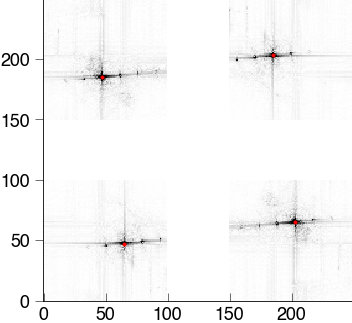

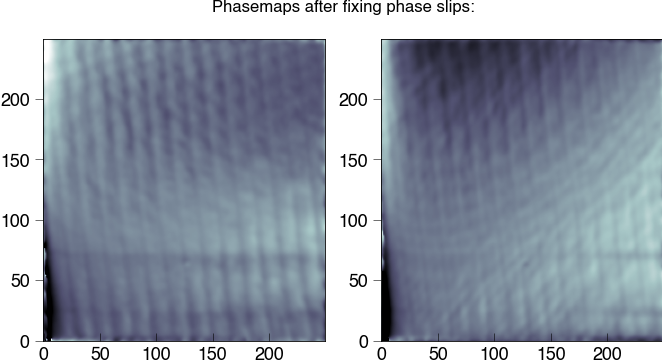

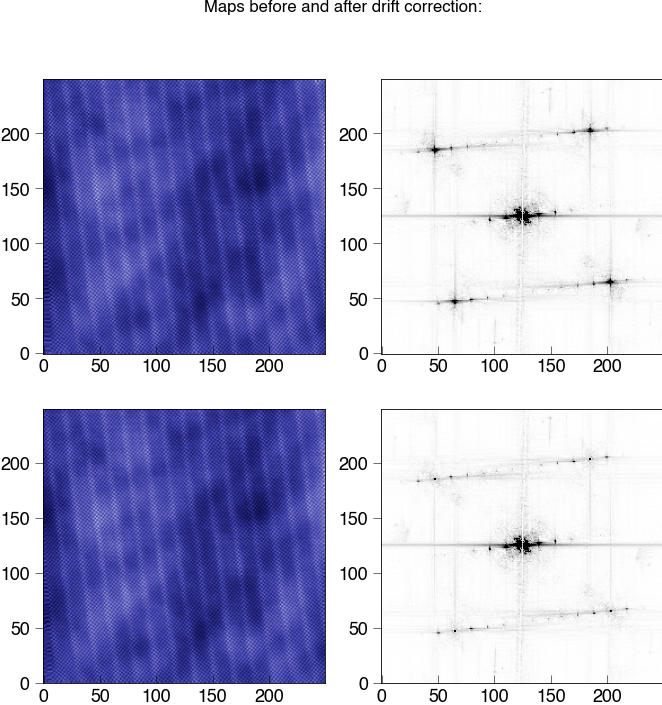

In [24]:
z_c2, param2 = dfc.find_drift_parameter(z_c1, r=0.2, w=0.1, min_dist=10, bp_c=bp_c, 
                                      sigma=20, method='lockin')

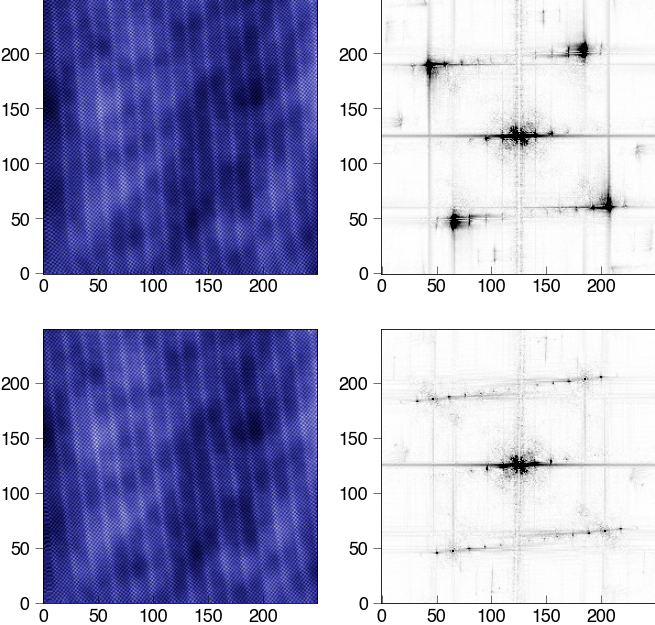

In [26]:
dfc.display(d1.z, z_c2)


# SS 40 nm dos map

In [61]:
f2 = h5py.File('reconstruction_rmv_outliers_250x250_40nm.h5','r')
d2 = stmpy.io.Spy()
d2.en, d2.fft, d2.liy = convert_fft(f2)

In [88]:
t2 = stmpy.load("2022-09-05_BSCCO_SparseSamplingTopo001.sxm")
d2.z = rot90(stmpy.tools.lineSubtract(t2.Z, 2))
shape(t2.Z)

(250, 250)

In [79]:
temp = loadtxt('our method 10.txt')
test = copy(temp)
# test = stmpy.tools.nsigma_local(temp)

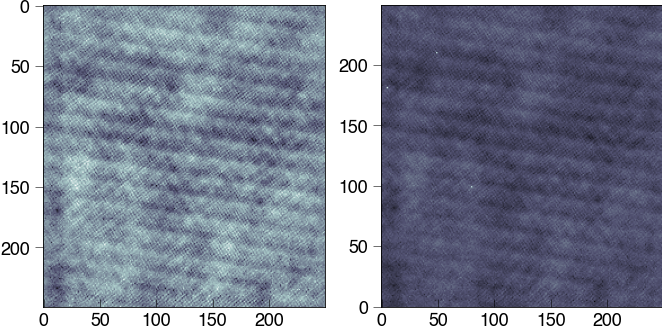

In [80]:
fig,ax=subplots(1,2,figsize=[8,4])
ax[0].imshow(d2.liy[-1], origin='upper')
ax[1].imshow(test)

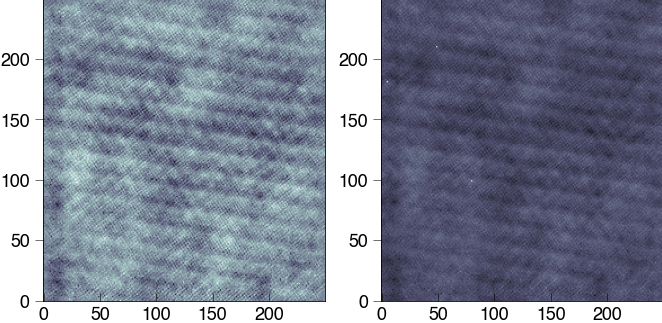

In [81]:
jens = d2.liy[-1][::-1,:]
truth = d1.LIY[-1].T

fig,ax=subplots(1,2,figsize=[8,4])
ax[0].imshow(jens)
ax[1].imshow(test)

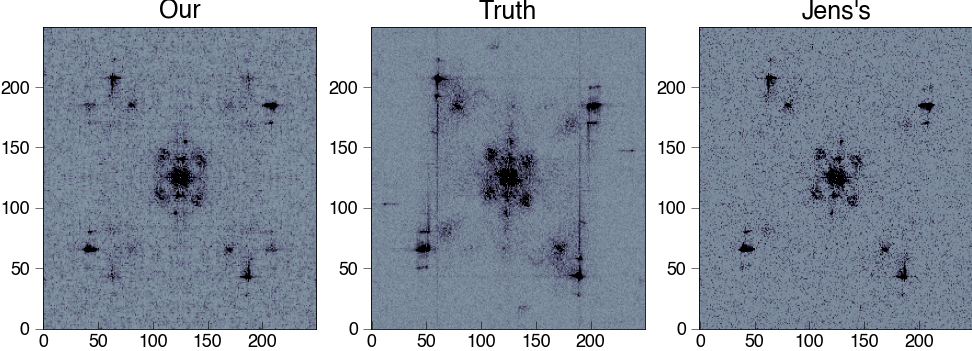

In [82]:
jens_fft = stmpy.tools.fft(jens, zeroDC=True)
test_fft = stmpy.tools.fft(test, zeroDC=True)
truth_fft = stmpy.tools.fft(truth, zeroDC=True)


c1 = mean(jens_fft)
s1 = std(jens_fft)

c2 = mean(test_fft)
s2 = std(test_fft)

c3 = mean(truth_fft)
s3 = std(truth_fft)

fig,ax=subplots(1,3,figsize=[12,4])
ax[2].imshow(jens_fft, clim=[c1-3*s1, c1+3*s1])
ax[1].imshow(truth_fft, clim=[c3-3*s3, c3+3*s3])
ax[0].imshow(test_fft, clim=[c2-3*s2, c2+3*s2])

titles = ['Our', 'Truth', "Jens's"]
for i, ix in enumerate(ax):
    ix.set_title(titles[i])

In [41]:
# savetxt("jens result.txt", jens)

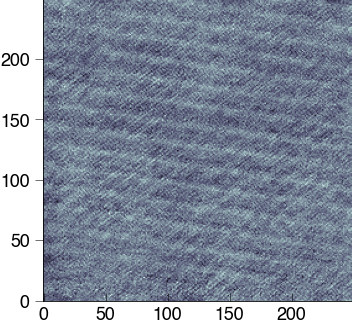

In [34]:
residual = test - mean(test) / mean(jens) * jens

imshow(residual)

In [35]:
print(std(test)/mean(test), std(jens)/mean(jens))

0.07210245426289429 0.05241246056737175


In [36]:
print(std(test), std(jens))

47.662131065323514 0.0001407689412906684


## Drift correct the map

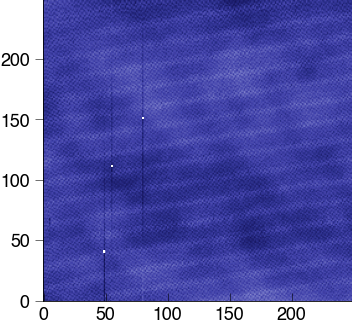

In [33]:
c = mean(d2.z)
s = std(d2.z)
figure()
imshow(d2.z, cmap=stmpy.cm.blue2, clim=[c-5*s, c+5*s], origin='lower')

The coordinates of the Bragg peaks are:
array([[ 63,  43],
       [187, 207],
       [210,  65],
       [ 40, 185]])

The coordinates of the Q vectors are:
array([[-61, -81],
       [ 63,  83],
       [ 86, -59],
       [-84,  61]])


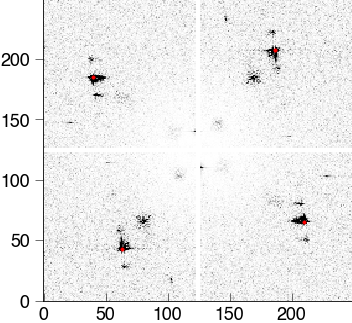

In [34]:
liy_topo = mean(d2.liy, axis=0)
bp1 = dfc.findBraggs(liy_topo, r=0.2, w=0.01, show=True)

In [9]:
bp_c = dfc.generate_bp(liy_topo, bp=bp1, orient=arctan2(-81, -61), even_out=True)
bp_c

array([[ 62,  42],
       [ 42, 186],
       [186, 206],
       [206,  62]])

The coordinates of the Bragg peaks are:
array([[127, 110],
       [123, 140],
       [ 63,  43],
       [187, 207],
       [125, 124],
       [125, 126]])

The coordinates of the Q vectors are:
array([[  3, -14],
       [ -1,  16],
       [-61, -81],
       [ 63,  83],
       [  1,   0],
       [  1,   2]])


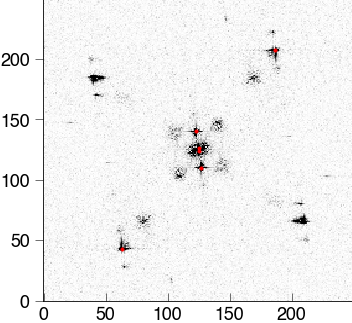

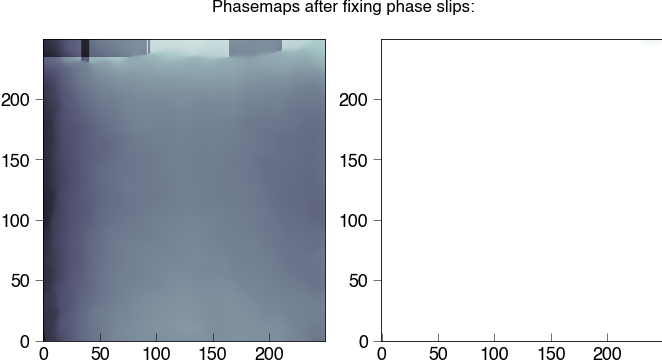

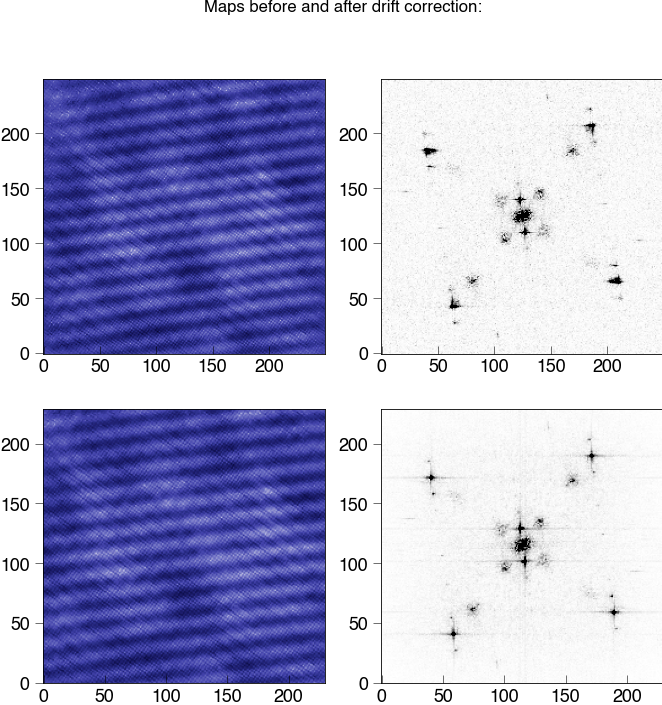

In [10]:
z_c1, param1 = dfc.find_drift_parameter(liy_topo, bp_c=bp_c, cut2=10,
                                      sigma=8, method='lockin')

The coordinates of the Bragg peaks are:
array([[ 40, 171],
       [190,  59],
       [ 59,  40],
       [171, 190]])

The coordinates of the Q vectors are:
array([[-74,  57],
       [ 76, -55],
       [-55, -74],
       [ 57,  76]])


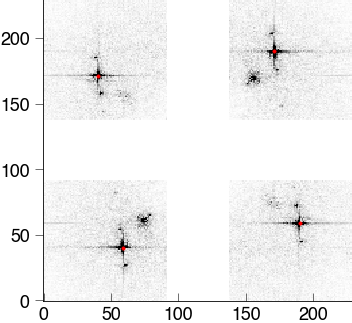

In [11]:
bp2 = dfc.findBraggs(z_c1, rspace=True, r=0.2, w=0.1, min_dist=20, show=True)

In [59]:
bp_c2 = dfc.generate_bp(z_c1, bp=bp2, orient=arctan2(-74, -55), even_out=True)
bp_c2

array([[ 58,  40],
       [ 40, 170],
       [170, 188],
       [188,  58]])

The coordinates of the Bragg peaks are:
array([[113, 129],
       [117, 101],
       [115, 114],
       [115, 116],
       [ 40, 171],
       [190,  59],
       [ 59,  40],
       [171, 190]])

The coordinates of the Q vectors are:
array([[ -1,  15],
       [  3, -13],
       [  1,   0],
       [  1,   2],
       [-74,  57],
       [ 76, -55],
       [-55, -74],
       [ 57,  76]])


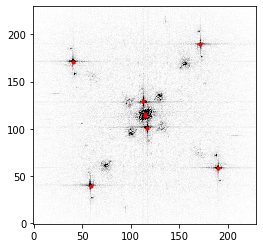

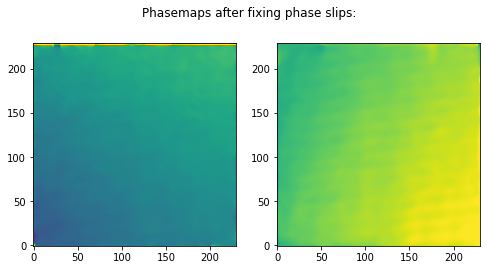

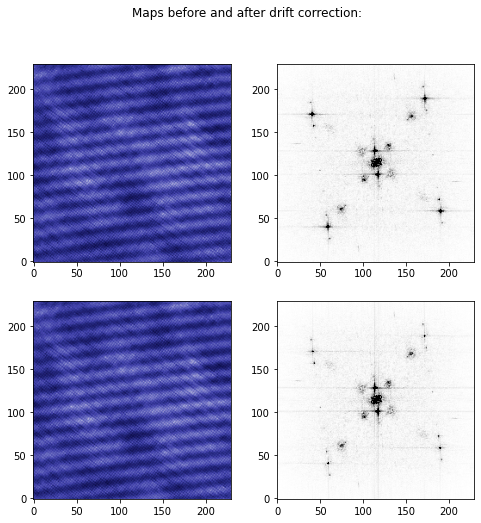

In [60]:
z_c2, param2 = dfc.find_drift_parameter(z_c1, bp_c=bp_c2, # cut2=[10,21,10,21],
                                      sigma=10, method='lockin')

In [61]:
liy_c_temp = dfc.apply_drift_parameter(d2.liy, p=param1)
d2.liy_c = dfc.apply_drift_parameter(liy_c_temp, p=param2)

In [62]:
d2.fft_c = stmpy.tools.fft(d2.liy_c, zeroDC=True)

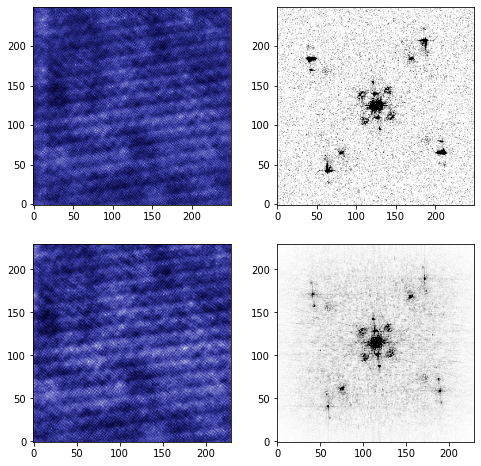

In [63]:
dfc.display(d2.liy[-1], d2.liy_c[-1])

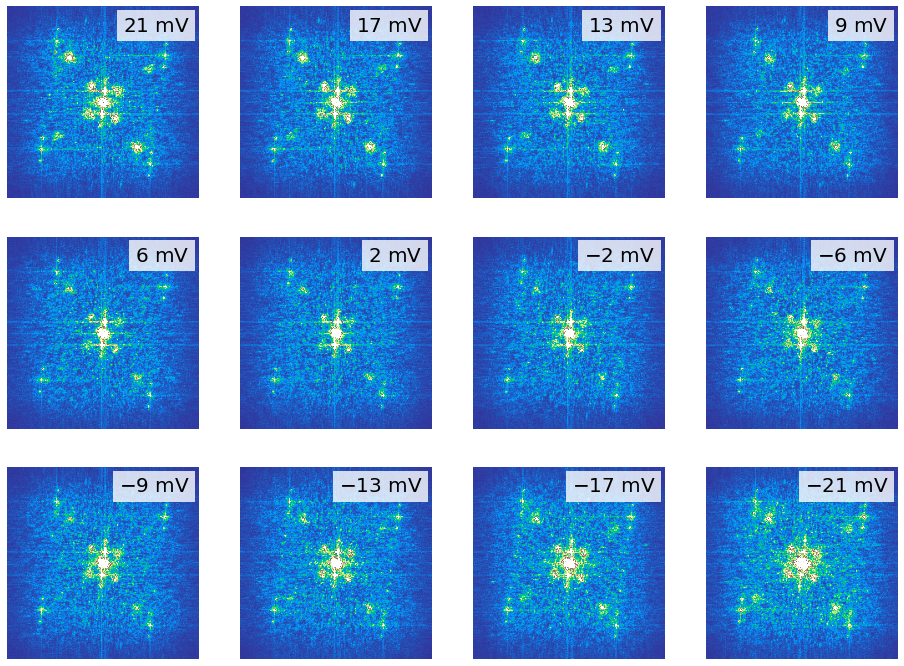

In [64]:
fig,ax=subplots(3,4,figsize=[16,12])
for i in range(len(d2.en)):
    c = mean(d2.fft_c[i])
    s = std(d2.fft_c[i])
    ax[i//4, i%4].imshow(d2.fft_c[i], cmap=stmpy.cm.terrain, clim=[0, c+3*s])
    ax[i//4, i%4].axis('off')
    stmpy.image.add_label(r"${}$ mV".format(int(d2.en[i]*1e3)),ax=ax[i//4, i%4])
# savefig('09-05 conventional map.png',dpi=400,bbox_inches='tight', pad_inches=0.02)

The coordinates of the Bragg peaks are:
array([[189,  59],
       [ 41, 171],
       [171, 189],
       [ 59,  41]])

The coordinates of the Q vectors are:
array([[ 75, -55],
       [-73,  57],
       [ 57,  75],
       [-55, -73]])


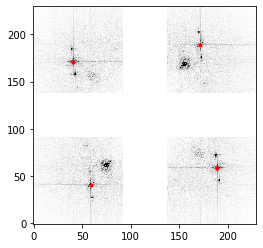

In [65]:
bpx = dfc.findBraggs(z_c2, rspace=True, r=0.2, w=0.1, min_dist=20, show=True)

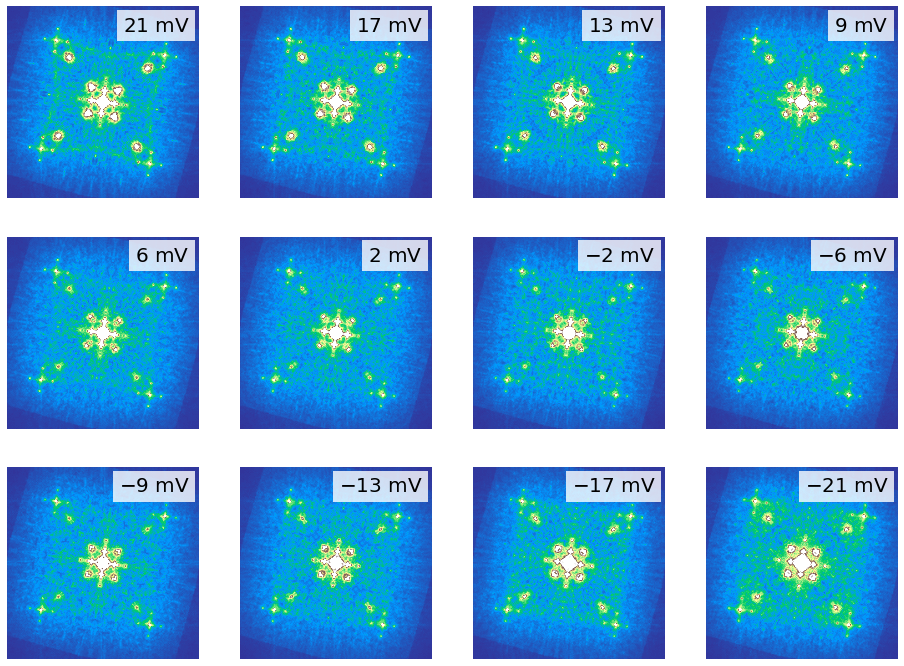

In [67]:
d2.fft_c_symm = stmpy.tools.symmetrize(d2.fft_c, n=4, bp=[ 59,  41])

fig,ax=subplots(3,4,figsize=[16,12])
for i in range(len(d2.en)):
    c = mean(d2.fft_c_symm[i])
    s = std(d2.fft_c_symm[i])
    ax[i//4, i%4].imshow(d2.fft_c_symm[i], cmap=stmpy.cm.terrain, clim=[0, c+3*s])
    ax[i//4, i%4].axis('off')
    stmpy.image.add_label(r"${}$ mV".format(int(d2.en[i]*1e3)),ax=ax[i//4, i%4])
# savefig('09-05 conventional map.png',dpi=400,bbox_inches='tight', pad_inches=0.02)

# SS 65 nm dos map

In [36]:
f3 = h5py.File('reconstruction_rmv_outliers_380x380_65nm.h5','r')
d3 = stmpy.io.Spy()
d3.en, d3.fft, d3.liy = convert_fft(f3)


In [37]:
t3 = stmpy.load("2022-09-05_BSCCO_SparseSamplingTopo002.sxm")
# d3.z = stmpy.tools.lineSubtract(rot90(t3.Z), 2)
d3.z = rot90(stmpy.tools.lineSubtract(t3.Z, 2))



## Drift correct the map

### Drift correction with topo

The coordinates of the Bragg peaks are:
array([[ 86,  55],
       [294, 325],
       [333,  92],
       [ 47, 288]])

The coordinates of the Q vectors are:
array([[-103, -134],
       [ 105,  136],
       [ 144,  -97],
       [-142,   99]])


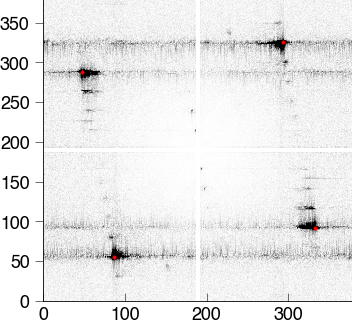

In [58]:
bp1 = dfc.findBraggs(d3.z, r=0.2, w=0.01, show=True)

In [59]:
bp_c = dfc.generate_bp(d3.z, bp=bp1, orient=arctan2(-134, -103), even_out=True)
bp_c

array([[ 85,  53],
       [ 53, 293],
       [293, 325],
       [325,  85]])

The coordinates of the Bragg peaks are:
array([[191, 192],
       [194, 166],
       [186, 214]])

The coordinates of the Q vectors are:
array([[  2,   3],
       [  5, -23],
       [ -3,  25]])


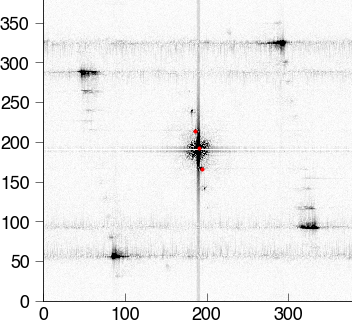

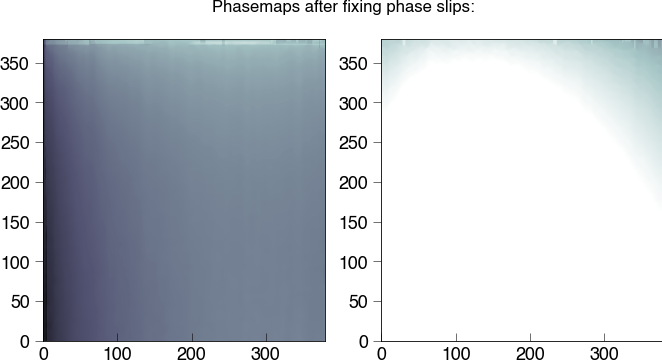

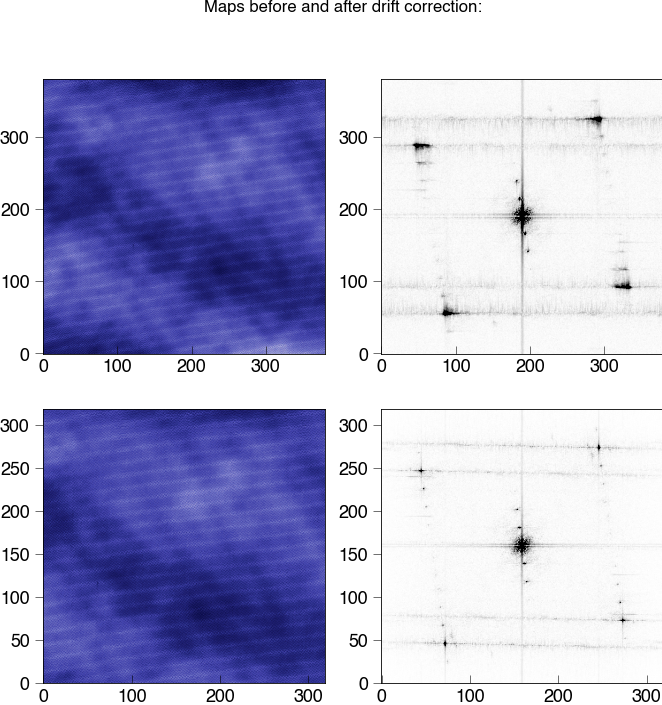

In [64]:
z_c1, param1 = dfc.find_drift_parameter(d3.z, bp_c=bp_c, cut2=[50,11,50,11],
                                      sigma=20, method='lockin')

The coordinates of the Bragg peaks are:
array([[273,  72],
       [ 45, 246],
       [ 72,  45],
       [246, 273]])

The coordinates of the Q vectors are:
array([[ 114,  -87],
       [-114,   87],
       [ -87, -114],
       [  87,  114]])


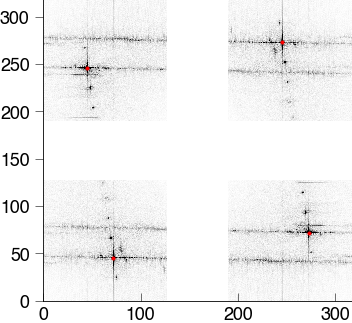

In [65]:
bp2 = dfc.findBraggs(z_c1, rspace=True, r=0.2, w=0.1, min_dist=20, show=True)

In [67]:
bp_c2 = dfc.generate_bp(z_c1, bp=bp2, orient=arctan2(-114, -87), even_out=True)
bp_c2

array([[ 71,  45],
       [ 45, 247],
       [247, 273],
       [273,  71]])

The coordinates of the Bragg peaks are:
array([[159, 160],
       [273,  72],
       [ 45, 246],
       [ 72,  45],
       [246, 273],
       [162, 138],
       [156, 180]])

The coordinates of the Q vectors are:
array([[   0,    1],
       [ 114,  -87],
       [-114,   87],
       [ -87, -114],
       [  87,  114],
       [   3,  -21],
       [  -3,   21]])


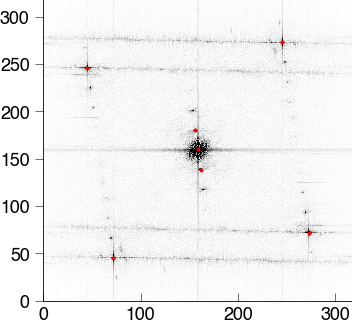

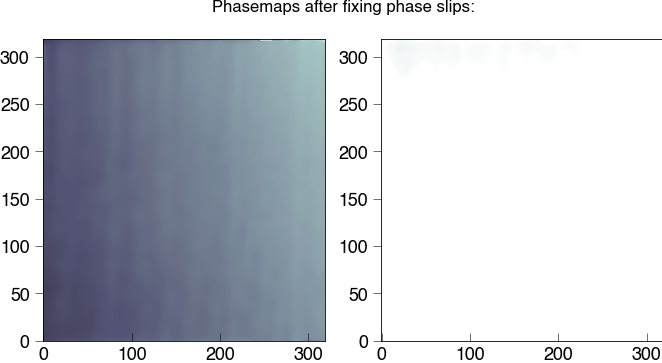

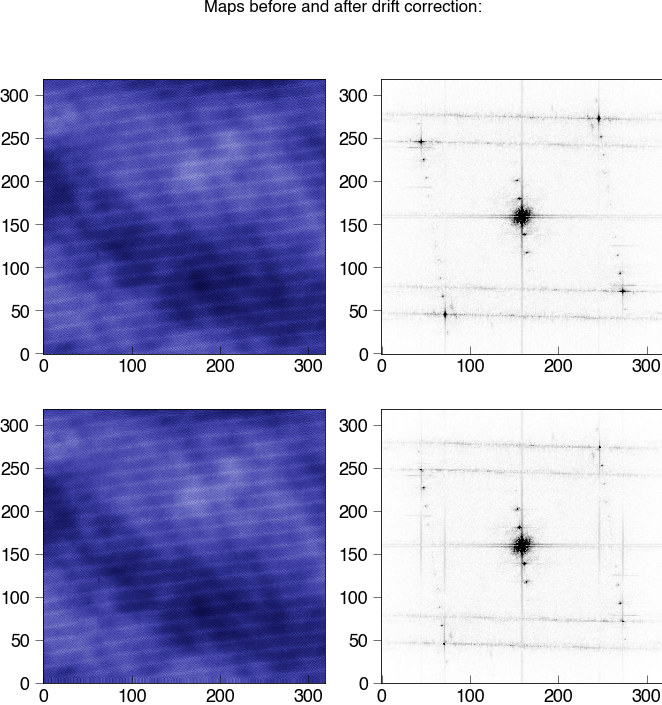

In [68]:
z_c2, param2 = dfc.find_drift_parameter(z_c1, bp_c=bp_c2, # cut2=[50,11,50,11],
                                      sigma=10, method='lockin')

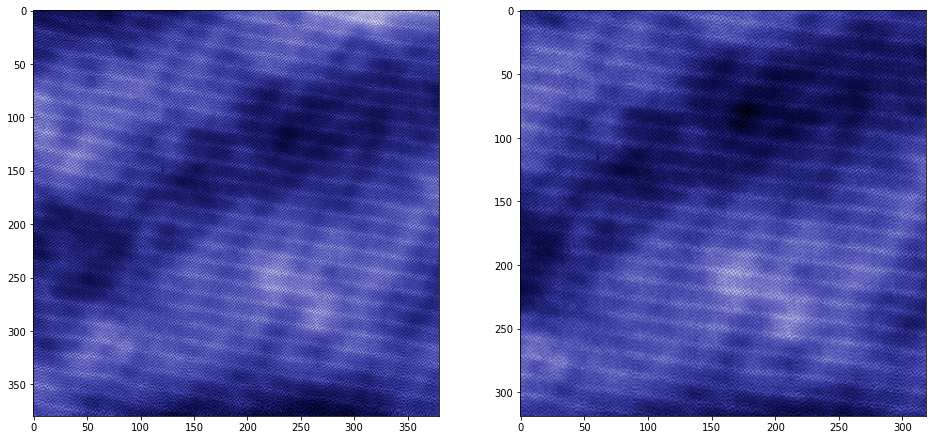

In [36]:
fig,ax=subplots(1,2,figsize=[16,8])
ax[0].imshow(d3.z, cmap=stmpy.cm.blue2)
ax[1].imshow(z_c2, cmap=stmpy.cm.blue2)

In [37]:
liy_c_temp = dfc.apply_drift_parameter(d3.liy, p=param1)
d3.liy_c = dfc.apply_drift_parameter(liy_c_temp, p=param2)

In [38]:
d3.fft_c = stmpy.tools.fft(d3.liy_c, zeroDC=True)

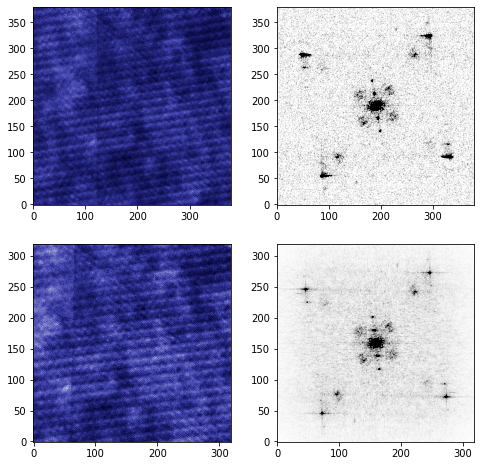

In [39]:
dfc.display(d3.liy[-1], d3.liy_c[-1])

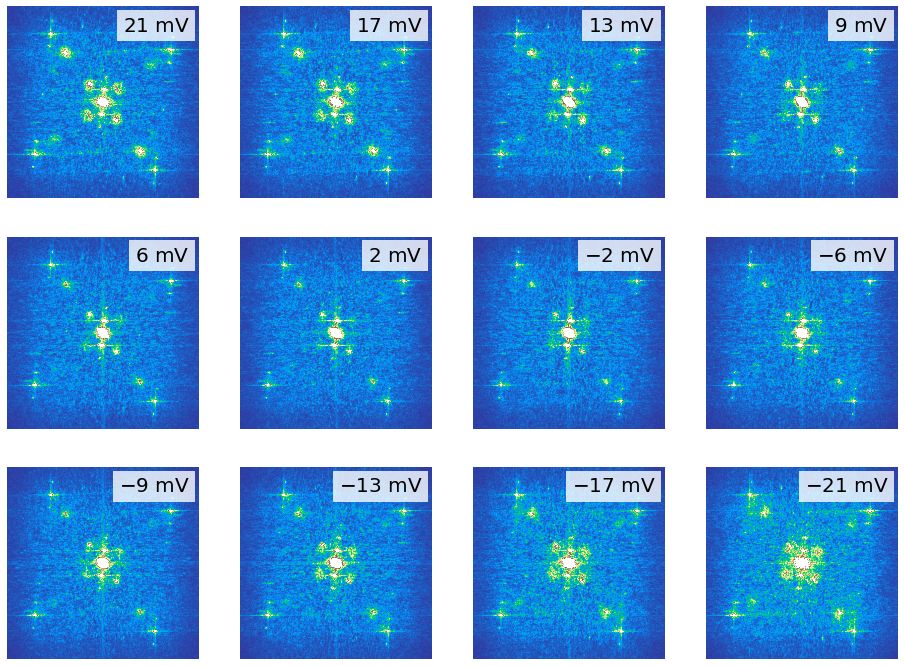

In [40]:
fig,ax=subplots(3,4,figsize=[16,12])
for i in range(len(d3.en)):
    c = mean(d3.fft_c[i])
    s = std(d3.fft_c[i])
    ax[i//4, i%4].imshow(d3.fft_c[i], cmap=stmpy.cm.terrain, clim=[0, c+3*s])
    ax[i//4, i%4].axis('off')
    stmpy.image.add_label(r"${}$ mV".format(int(d3.en[i]*1e3)),ax=ax[i//4, i%4])
# savefig('09-05 conventional map.png',dpi=400,bbox_inches='tight', pad_inches=0.02)

The coordinates of the Bragg peaks are:
array([[ 72,  46],
       [246, 272],
       [272,  72],
       [ 46, 246]])

The coordinates of the Q vectors are:
array([[ -87, -113],
       [  87,  113],
       [ 113,  -87],
       [-113,   87]])


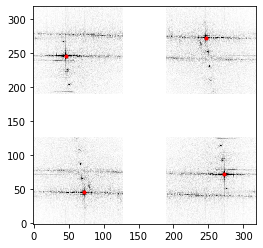

In [41]:
bpx = dfc.findBraggs(z_c2, rspace=True, r=0.2, w=0.1, min_dist=20, show=True)

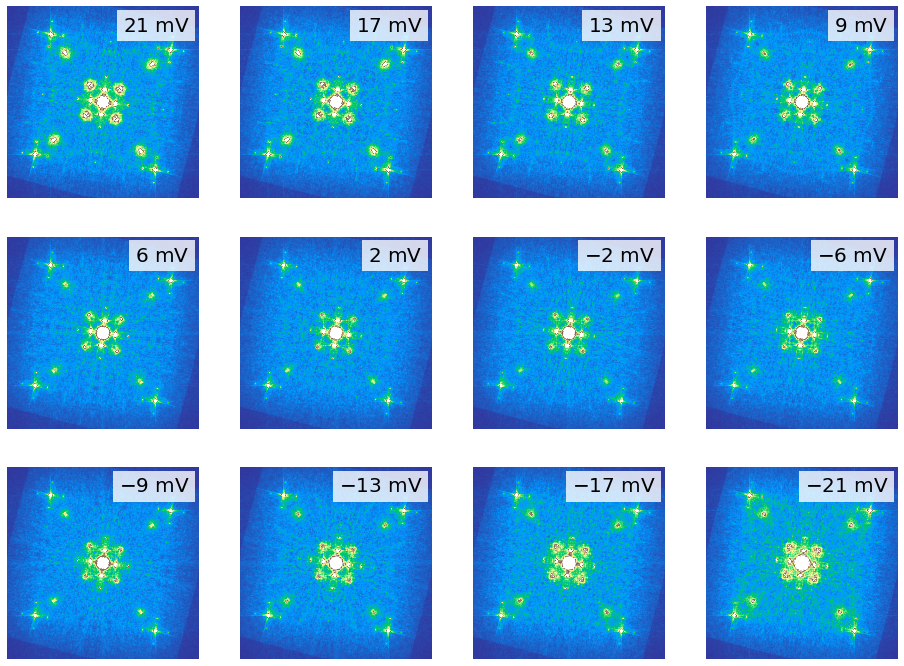

In [42]:
d3.fft_c_symm = stmpy.tools.symmetrize(d3.fft_c, n=4, bp=[ 72,  46])

fig,ax=subplots(3,4,figsize=[16,12])
for i in range(len(d3.en)):
    c = mean(d3.fft_c_symm[i])
    s = std(d3.fft_c_symm[i])
    ax[i//4, i%4].imshow(d3.fft_c_symm[i], cmap=stmpy.cm.terrain, clim=[0, c+3*s])
    ax[i//4, i%4].axis('off')
    stmpy.image.add_label(r"${}$ mV".format(int(d3.en[i]*1e3)),ax=ax[i//4, i%4])
# savefig('09-05 conventional map.png',dpi=400,bbox_inches='tight', pad_inches=0.02)

### Drift correct with the dos map

The coordinates of the Bragg peaks are:
array([[333,  92],
       [ 47, 288],
       [ 86,  55],
       [294, 325]])

The coordinates of the Q vectors are:
array([[ 144,  -97],
       [-142,   99],
       [-103, -134],
       [ 105,  136]])


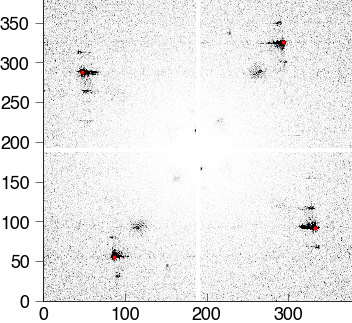

In [47]:
liy_topo3 = mean(d3.liy, axis=0)
bp1 = dfc.findBraggs(liy_topo3, r=0.5, w=0.01, show=True)

In [48]:
bp_c = dfc.generate_bp(liy_topo3, bp=bp1, orient=arctan2(-134, -103), even_out=True)
bp_c

array([[ 85,  53],
       [ 53, 293],
       [293, 325],
       [325,  85]])

The coordinates of the Bragg peaks are:
array([[194, 166],
       [186, 214],
       [189, 188],
       [191, 192]])

The coordinates of the Q vectors are:
array([[  5, -23],
       [ -3,  25],
       [  0,  -1],
       [  2,   3]])


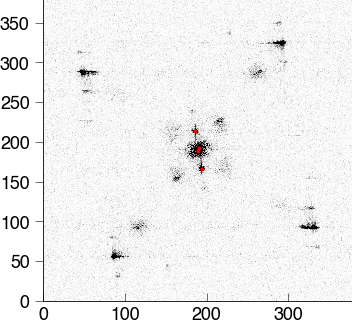

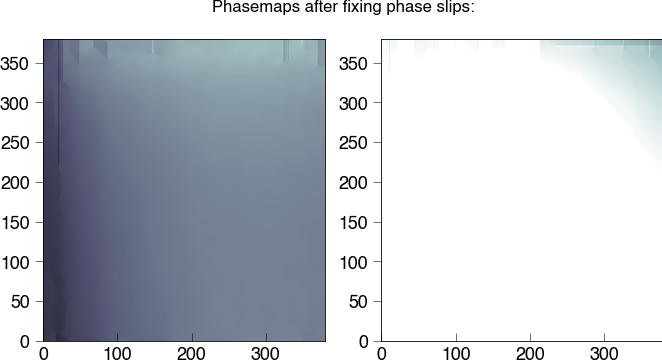

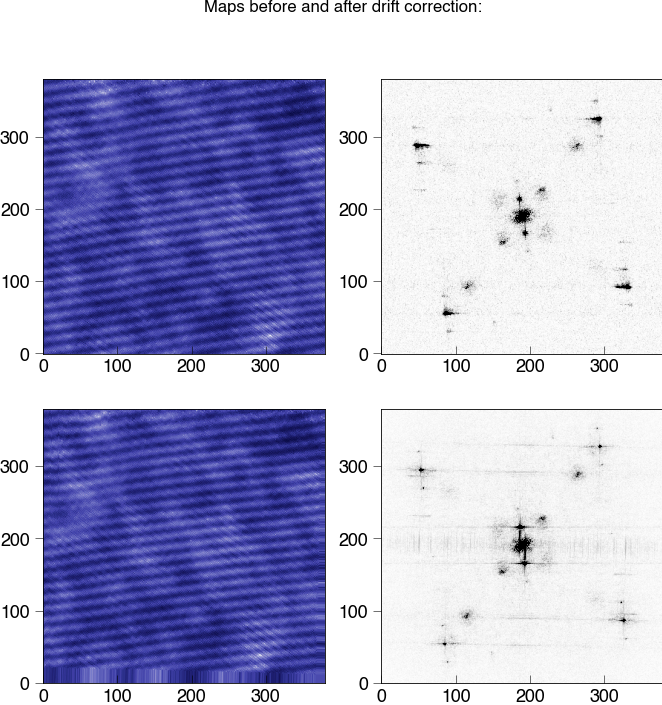

In [54]:
z_c1, param1 = dfc.find_drift_parameter(liy_topo3, bp_c=bp_c, # cut2=10,
                                      sigma=11, method='lockin')

The coordinates of the Bragg peaks are:
array([[ 86,  54],
       [294, 326],
       [327,  86],
       [ 53, 294]])

The coordinates of the Q vectors are:
array([[-103, -135],
       [ 105,  137],
       [ 138, -103],
       [-136,  105]])


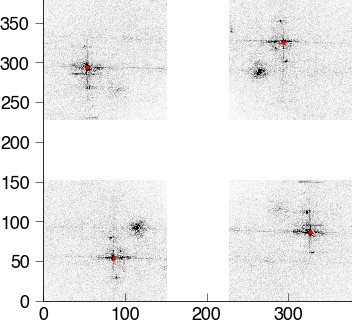

In [55]:
bp2 = dfc.findBraggs(z_c1, rspace=True, r=0.2, w=0.1, min_dist=20, show=True)

In [56]:
bp_c2 = dfc.generate_bp(z_c1, bp=bp2, orient=arctan2(-135, -103), even_out=True)
bp_c2

array([[ 85,  53],
       [ 53, 293],
       [293, 325],
       [325,  85]])

The coordinates of the Bragg peaks are:
array([[193, 165],
       [187, 215],
       [ 86,  54],
       [294, 326],
       [327,  86],
       [ 53, 294],
       [189, 188]])

The coordinates of the Q vectors are:
array([[   4,  -24],
       [  -2,   26],
       [-103, -135],
       [ 105,  137],
       [ 138, -103],
       [-136,  105],
       [   0,   -1]])


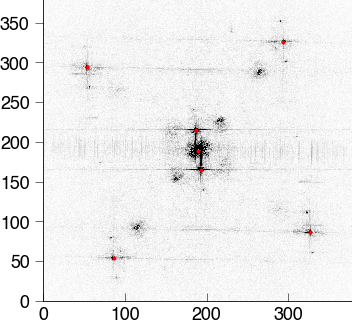

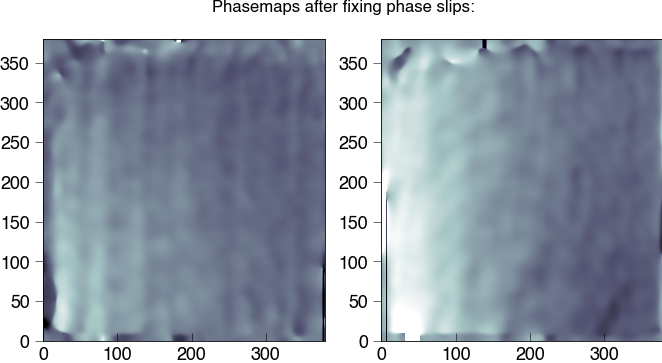

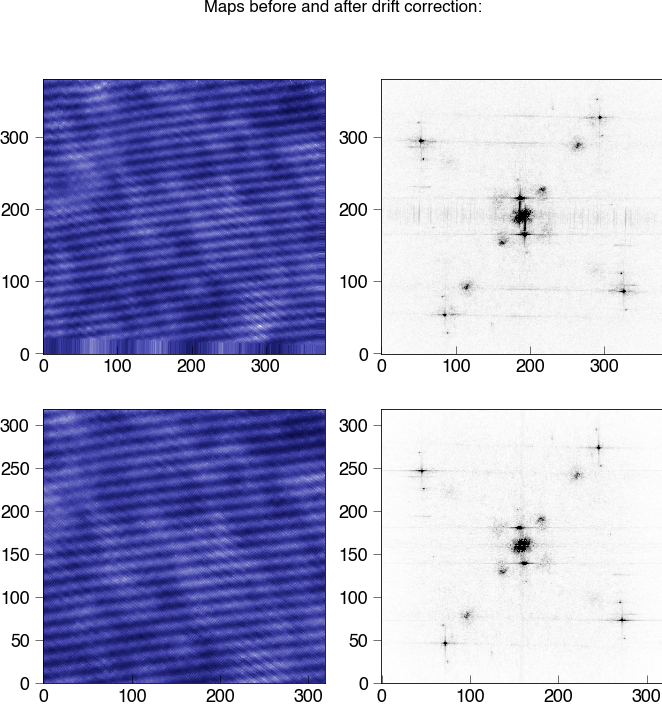

In [57]:
z_c2, param2 = dfc.find_drift_parameter(z_c1, bp_c=bp_c2, cut2=[50,11,50,11],
                                      sigma=10, method='lockin')

# Compare the three datasets

## Compare the raw QPI

In [128]:
liy1 = zeros_like(d1.en)
for i in range(len(d1.en)):
    liy1[i] = mean(d1.LIY[i])
    
liy2 = zeros_like(d2.en)
for i in range(len(d2.en)):
    liy2[i] = mean(d2.liy[i])
    
liy3 = zeros_like(d3.en)
for i in range(len(d3.en)):
    liy3[i] = mean(d3.liy[i])

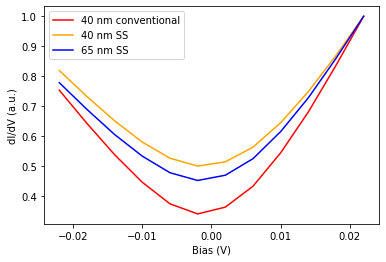

In [146]:
figure(figsize=[6,4])
plot(d1.en, liy1/liy1[0], 'r', label="40 nm conventional")
plot(d2.en, liy2/liy2[0], 'orange', label="40 nm SS")
plot(d3.en, liy3/liy3[0], 'b', label="65 nm SS")

legend()
xlabel('Bias (V)')
ylabel('dI/dV (a.u.)')

# savefig("dIdV comparison.png", dpi=400, bbox_inches='tight', pad_inches=0.01)

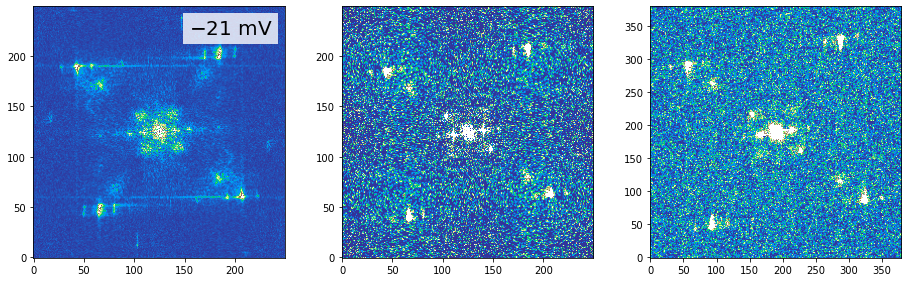

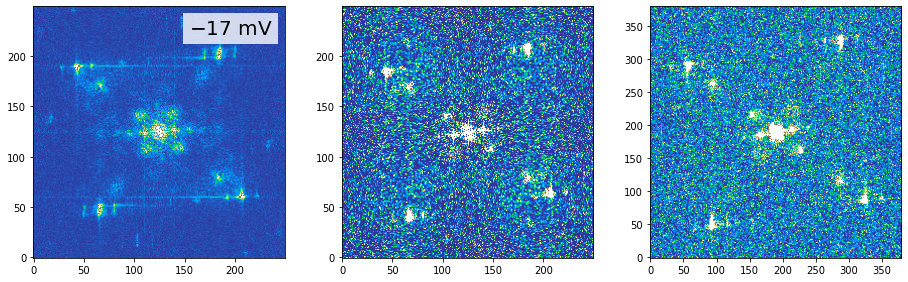

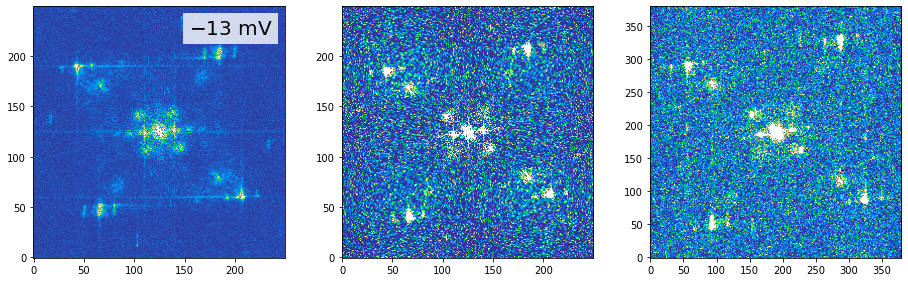

In [151]:
for i in range(3):
    fig,ax=subplots(1,3,figsize=[13,4])
    c1 = mean(d1.fft[-i-1])
    s1 = std(d1.fft[-i-1])
    c2 = mean(d2.fft[-i-1])
    s2 = std(d2.fft[-i-1])
    c3 = mean(d3.fft[-i-1])
    s3 = std(d3.fft[-i-1])
    ax[0].imshow(d1.fft[-i-1], cmap=stmpy.cm.terrain, clim=[0, c1+10*s1], origin='lower')
    ax[1].imshow(rot90(d2.fft[-i-1]), cmap=stmpy.cm.terrain, clim=[0, c2+0.1*s2], origin='lower')    
    ax[2].imshow(rot90(d3.fft[-i-1]), cmap=stmpy.cm.terrain, clim=[0, c3+0.1*s3], origin='lower')    
    stmpy.image.add_label(r"${}$ mV".format(int(d1.en[-i-1]*1e3)), ax=ax[0])
    tight_layout()
#     savefig("liy fft layer comparison at {} mV new.png".format(int(d1.en[-i-1]*1e3)), 
#             dpi=400, bbox_inches='tight', pad_inches=0.01)

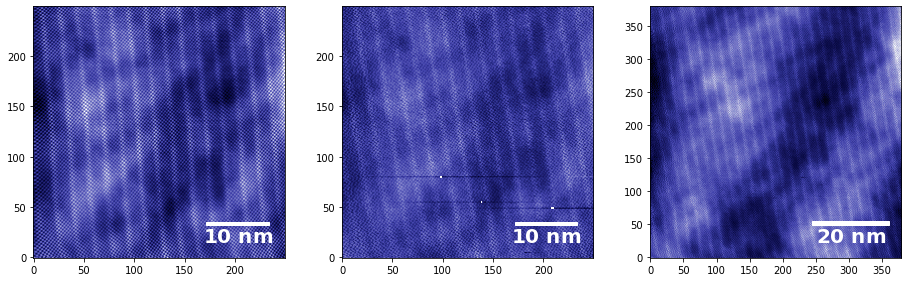

In [184]:
# for i in range(3):
fig,ax=subplots(1,3,figsize=[13,4])
c1 = mean(d1.z)
s1 = std(d1.z)
c2 = mean(d2.z)
s2 = std(d2.z)
c3 = mean(d3.z)
s3 = std(d3.z)
ax[0].imshow(d1.z, cmap=stmpy.cm.blue2, clim=[c1-3*s1, c1+3*s1], origin='lower')
ax[1].imshow((d2.z), cmap=stmpy.cm.blue2, clim=[c2-3*s2, c2+3*s2], origin='lower')    
ax[2].imshow((d3.z), cmap=stmpy.cm.blue2, clim=[c3-3*s3, c3+3*s3], origin='lower')    
stmpy.image.add_scale_bar(10, imgsize=40, imgpixels=250, ax=ax[0])
stmpy.image.add_scale_bar(10, imgsize=40, imgpixels=250, ax=ax[1])
stmpy.image.add_scale_bar(20, imgsize=65, imgpixels=380, ax=ax[2])

tight_layout()

# stmpy.image.add_label(r"${}$ mV".format(int(d1.en[-i-1]*1e3)), ax=ax[0])
savefig("../figures/topo comparison.png", dpi=400, bbox_inches='tight', pad_inches=0.01)

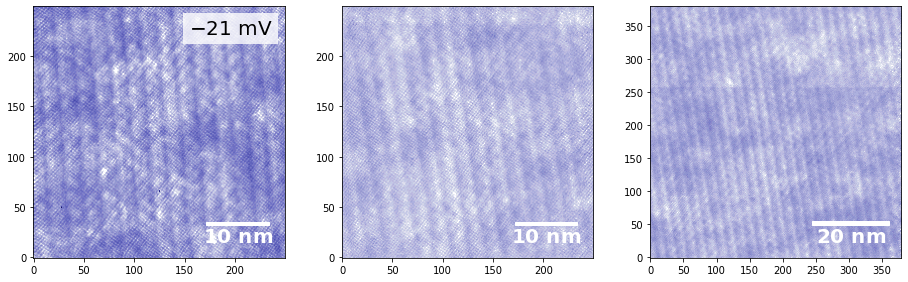

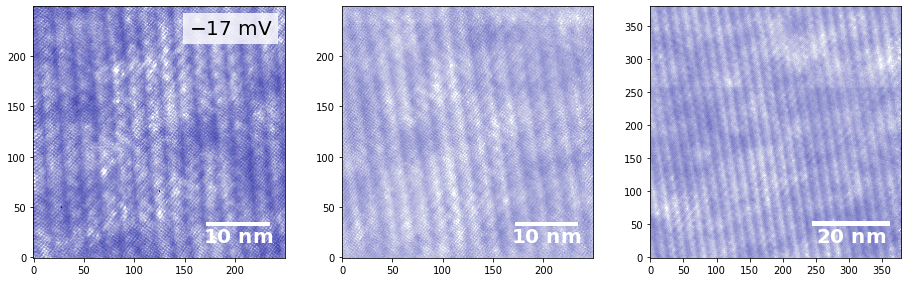

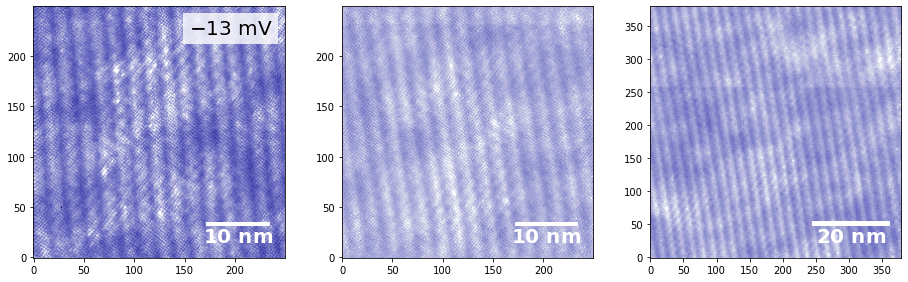

In [147]:
for i in range(3):
    fig,ax=subplots(1,3,figsize=[13,4])
    c1 = mean(d1.LIY[-i-1])
    s1 = std(d1.LIY[-i-1])
    c2 = mean(d2.liy[-i-1])
    s2 = std(d2.liy[-i-1])
    c3 = mean(d3.liy[-i-1])
    s3 = std(d3.liy[-i-1])
    
    ax[0].imshow(d1.LIY[-i-1], cmap=stmpy.cm.blue2, clim=[0, c1+3*s1], origin='lower')
    ax[1].imshow(rot90(d2.liy[-i-1]), cmap=stmpy.cm.blue2, clim=[0, c2+3*s2], origin='lower')    
    ax[2].imshow(rot90(d3.liy[-i-1]), cmap=stmpy.cm.blue2, clim=[0, c3+3*s3], origin='lower')    
    stmpy.image.add_label(r"${}$ mV".format(int(d1.en[-i-1]*1e3)), ax=ax[0])
    stmpy.image.add_scale_bar(10, imgsize=40, imgpixels=250, ax=ax[0])
    stmpy.image.add_scale_bar(10, imgsize=40, imgpixels=250, ax=ax[1])
    stmpy.image.add_scale_bar(20, imgsize=65, imgpixels=380, ax=ax[2])

    tight_layout()

    # stmpy.image.add_label(r"${}$ mV".format(int(d1.en[-i-1]*1e3)), ax=ax[0])
#     savefig("liy layer comparison at {} mV.png".format(int(d1.en[-i-1]*1e3)), 
#             dpi=400, bbox_inches='tight', pad_inches=0.01)

In [164]:
topo1 = stmpy.load("2022-09-06_BSCCO_0001.sxm")
topo2 = stmpy.load("2022-09-05_BSCCO_0001.sxm")
topo3 = stmpy.load("2022-09-05_BSCCO_0002.sxm")

topo1.z = stmpy.tools.lineSubtract(topo1.Z, 2)
topo2.z = stmpy.tools.lineSubtract(topo2.Z, 2)
topo3.z = stmpy.tools.lineSubtract(topo3.Z, 2)

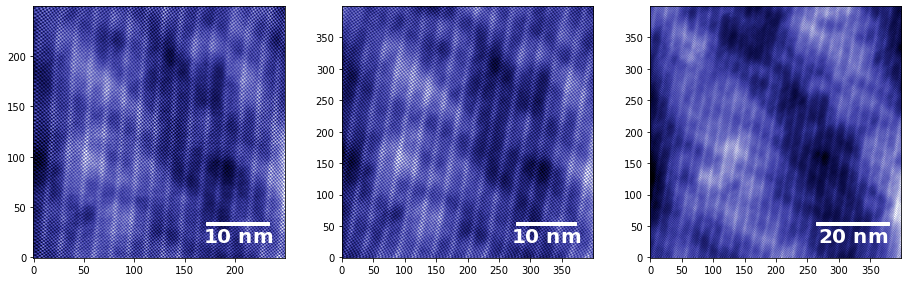

In [180]:
# for i in range(3):
fig,ax=subplots(1,3,figsize=[13,4])
c1 = mean(d1.z)
s1 = std(d1.z)
c2 = mean(topo2.z)
s2 = std(topo2.z)
c3 = mean(topo3.z)
s3 = std(topo3.z)
ax[0].imshow(d1.z[::-1], cmap=stmpy.cm.blue2, clim=[c1-3*s1, c1+3*s1], origin='lower')
ax[1].imshow((topo2.z), cmap=stmpy.cm.blue2, clim=[c2-3*s2, c2+3*s2], origin='lower')    
ax[2].imshow((topo3.z), cmap=stmpy.cm.blue2, clim=[c3-3*s3, c3+3*s3], origin='lower')    
stmpy.image.add_scale_bar(10, imgsize=40, imgpixels=250, ax=ax[0])
stmpy.image.add_scale_bar(10, imgsize=40, imgpixels=380, ax=ax[1])
stmpy.image.add_scale_bar(20, imgsize=65, imgpixels=380, ax=ax[2])

tight_layout()

# stmpy.image.add_label(r"${}$ mV".format(int(d1.en[-i-1]*1e3)), ax=ax[0])
savefig("../figures/topo comparison new.png", dpi=400, bbox_inches='tight', pad_inches=0.01)

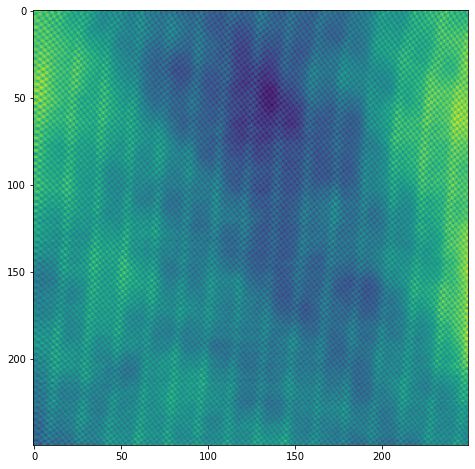

In [175]:
figure(figsize=[8,8])
imshow(d1.z)

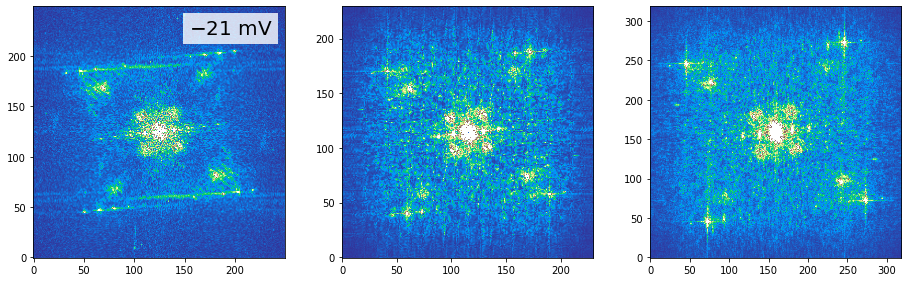

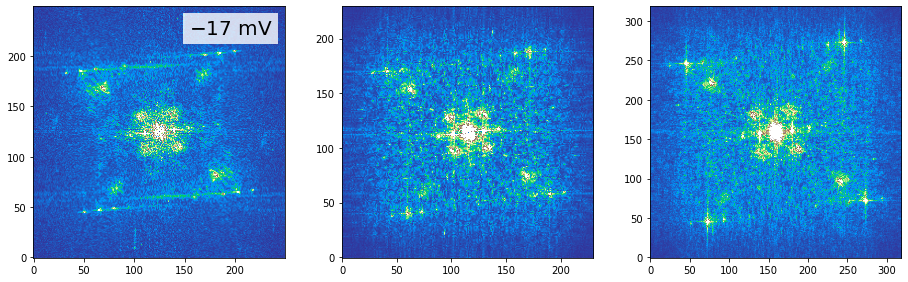

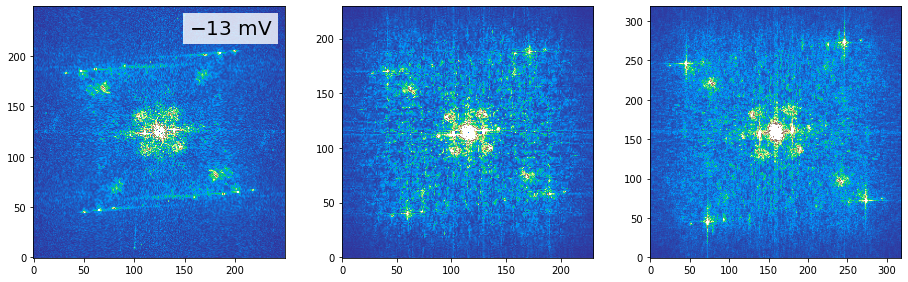

In [76]:
for i in range(3):
    fig,ax=subplots(1,3,figsize=[13,4])
    c1 = mean(d1.fft_c[-i-1])
    s1 = std( d1.fft_c[-i-1])
    c2 = mean(d2.fft_c[-i-1])
    s2 = std( d2.fft_c[-i-1])
    c3 = mean(d3.fft_c[-i-1])
    s3 = std( d3.fft_c[-i-1])
    ax[0].imshow(d1.fft_c[-i-1], cmap=stmpy.cm.terrain, clim=[0, c1+5*s1], origin='lower')
    ax[1].imshow(rot90(d2.fft_c[-i-1]), cmap=stmpy.cm.terrain, clim=[0, c2+3*s2], origin='lower')    
    ax[2].imshow(rot90(d3.fft_c[-i-1]), cmap=stmpy.cm.terrain, clim=[0, c3+3*s3], origin='lower')    
    stmpy.image.add_label(r"${}$ mV".format(int(d1.en[-i-1]*1e3)), ax=ax[0])
    tight_layout()
#     savefig("liy fft layer comparison dfc at {} mV new.png".format(int(d1.en[-i-1]*1e3)), 
#             dpi=400, bbox_inches='tight', pad_inches=0.01)

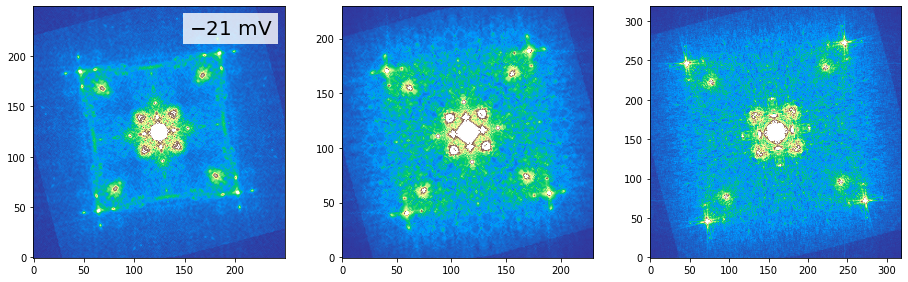

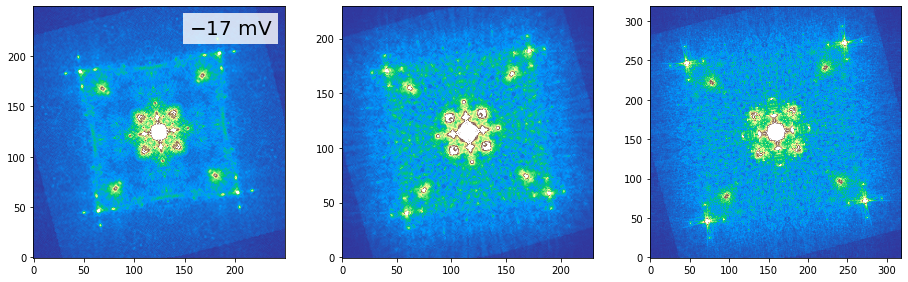

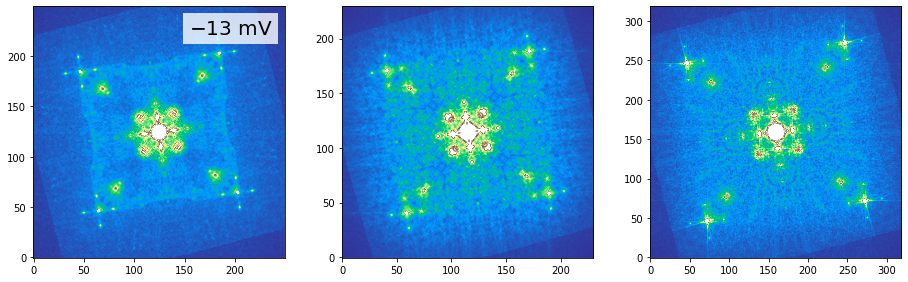

In [75]:
for i in range(3):
    fig,ax=subplots(1,3,figsize=[13,4])
    c1 = mean(d1.fft_c_symm[-i-1])
    s1 = std( d1.fft_c_symm[-i-1])
    c2 = mean(d2.fft_c_symm[-i-1])
    s2 = std( d2.fft_c_symm[-i-1])
    c3 = mean(d3.fft_c_symm[-i-1])
    s3 = std( d3.fft_c_symm[-i-1])
    ax[0].imshow(d1.fft_c_symm[-i-1], cmap=stmpy.cm.terrain, clim=[0, c1+5*s1], origin='lower')
    ax[1].imshow(rot90(d2.fft_c_symm[-i-1]), cmap=stmpy.cm.terrain, clim=[0, c2+3*s2], origin='lower')    
    ax[2].imshow(rot90(d3.fft_c_symm[-i-1]), cmap=stmpy.cm.terrain, clim=[0, c3+3*s3], origin='lower')    
    stmpy.image.add_label(r"${}$ mV".format(int(d1.en[-i-1]*1e3)), ax=ax[0])
    tight_layout()
#     savefig("liy fft layer comparison dfc and symm at {} mV new.png".format(int(d1.en[-i-1]*1e3)), 
#             dpi=400, bbox_inches='tight', pad_inches=0.01)

## Compare the linecuts

The coordinates of the Bragg peaks are:
array([[207,  60],
       [ 43, 190],
       [ 66,  51],
       [184, 199]])

The coordinates of the Q vectors are:
array([[ 83, -64],
       [-81,  66],
       [-58, -73],
       [ 60,  75]])


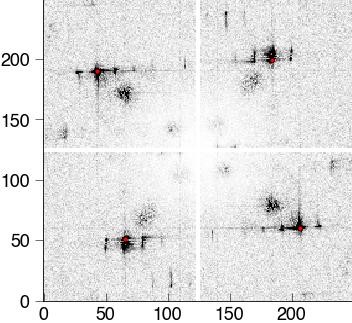

In [144]:
to_plot = d1

bp = dfc.findBraggs(to_plot.fft[0], min_dist=20, r=0.2, w=0.01, rspace=False, show=True)

p0 = array([ 66,  51])
p1 = array([184, 199])

p2 = array([207,  60])
p3 = array([ 43, 190])

p4 = (p0+p2)/2
p5 = (p1+p3)/2

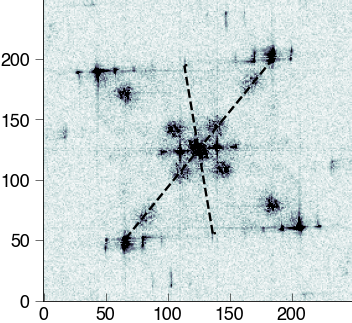

In [145]:
c = mean(to_plot.fft[0])
s = std(to_plot.fft[0])

figure(figsize=[4,4])
imshow(to_plot.fft[0], clim=[0, c+3*s])

r1, cut1 = stmpy.tools.linecut(to_plot.fft, p0=p0, p1=p1, width=5, show=True, ax=gca())
r2, cut2 = stmpy.tools.linecut(to_plot.fft, p0=p4, p1=p5, width=5, show=True, ax=gca())

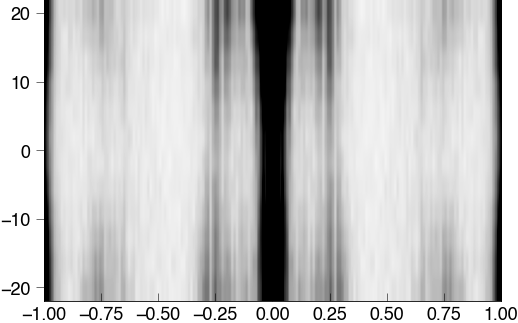

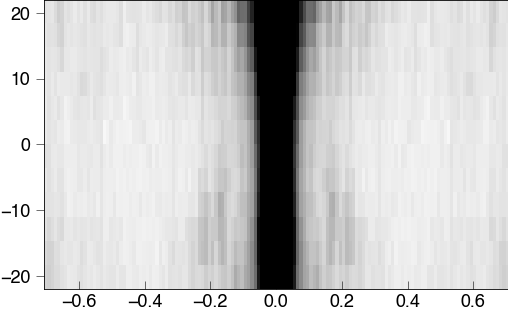

In [146]:
c = mean(cut1)
s = std(cut1)
figure(figsize=[6,4])
imshow(cut1, interpolation=None, clim=[0, c+1.5*s], cmap=stmpy.cm.gray_r,
       extent=[-1, 1, d1.en[-1]*1e3, d1.en[0]*1e3])
gca().set_aspect(3e-2)

c = mean(cut2)
s = std(cut2)
figure(figsize=[6,4])
imshow(cut2, interpolation=None, clim=[0, c+1.5*s], cmap=stmpy.cm.gray_r,
       extent=[-1/sqrt(2), 1/sqrt(2), d1.en[-1]*1e3, d1.en[0]*1e3])
gca().set_aspect(2e-2)

The coordinates of the Bragg peaks are:
array([[ 63,  43],
       [187, 207],
       [210,  65],
       [ 40, 185]])

The coordinates of the Q vectors are:
array([[-61, -81],
       [ 63,  83],
       [ 86, -59],
       [-84,  61]])


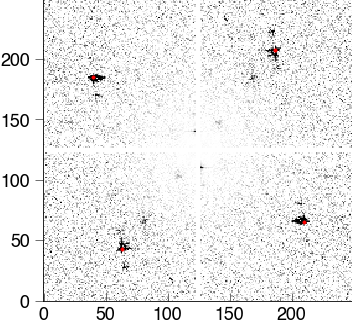

In [147]:
to_plot = d2

bp = dfc.findBraggs(to_plot.fft[0], min_dist=20, r=0.2, w=0.01, rspace=False, show=True)

p0 = array([ 63,  43])
p1 = array([187, 207])

p2 = array([210,  65])
p3 = array([ 40, 185])

p4 = (p0+p3)/2
p5 = (p1+p2)/2

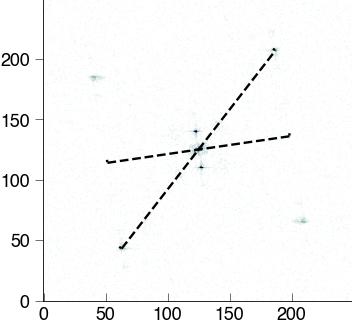

In [148]:
c = mean(to_plot.fft[0])
s = std(to_plot.fft[0])

figure(figsize=[4,4])
imshow(to_plot.fft[0], clim=[0, c+3*s])

r3, cut3 = stmpy.tools.linecut(to_plot.fft, p0=p0, p1=p1, width=5, show=True, ax=gca())
r4, cut4 = stmpy.tools.linecut(to_plot.fft, p0=p4, p1=p5, width=5, show=True, ax=gca())

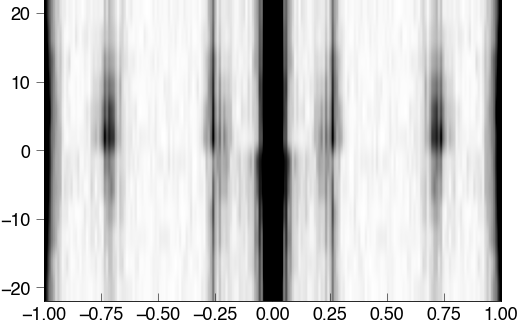

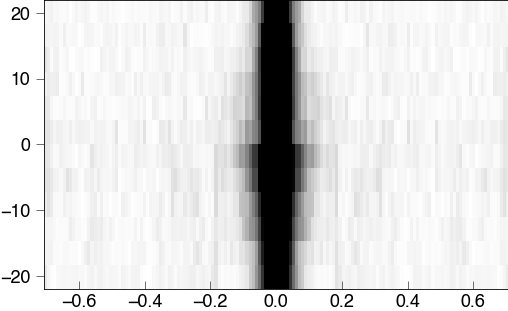

In [149]:
c = mean(cut3)
s = std(cut3)
figure(figsize=[6,4])
imshow(cut3, interpolation=None, clim=[0, c+1e-2*s], cmap=stmpy.cm.gray_r,
       extent=[-1, 1, to_plot.en[-1]*1e3, to_plot.en[0]*1e3])
gca().set_aspect(3e-2)

c = mean(cut4)
s = std(cut4)
figure(figsize=[6,4])
imshow(cut4, interpolation=None, clim=[0, c+1e-2*s], cmap=stmpy.cm.gray_r,
       extent=[-1/sqrt(2), 1/sqrt(2), to_plot.en[-1]*1e3, to_plot.en[0]*1e3])
gca().set_aspect(2e-2)

The coordinates of the Bragg peaks are:
array([[333,  92],
       [ 47, 288],
       [ 86,  55],
       [294, 325]])

The coordinates of the Q vectors are:
array([[ 144,  -97],
       [-142,   99],
       [-103, -134],
       [ 105,  136]])


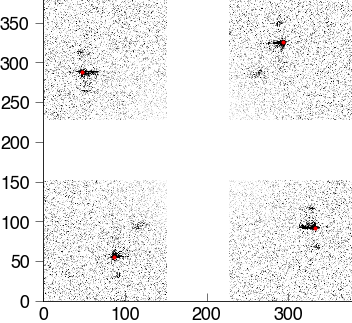

In [150]:
to_plot = d3

bp = dfc.findBraggs(to_plot.fft[0], min_dist=40, r=0.2, w=0.1, rspace=False, show=True)

p0 = array([ 86,  55])
p1 = array([294, 325])

p2 = array([333,  92])
p3 = array([ 47, 288])

p4 = (p0+p3)/2
p5 = (p1+p2)/2

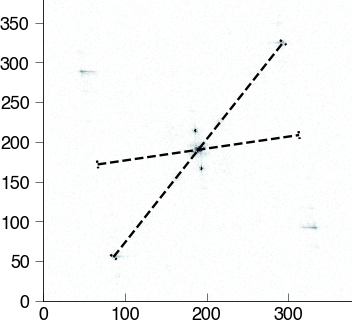

In [153]:
c = mean(to_plot.fft[0])
s = std(to_plot.fft[0])

figure(figsize=[4,4])
imshow(to_plot.fft[0], clim=[0, c+3*s])

r3, cut3 = stmpy.tools.linecut(to_plot.fft, p0=p0, p1=p1, width=10, show=True, ax=gca())
r4, cut4 = stmpy.tools.linecut(to_plot.fft, p0=p4, p1=p5, width=10, show=True, ax=gca())

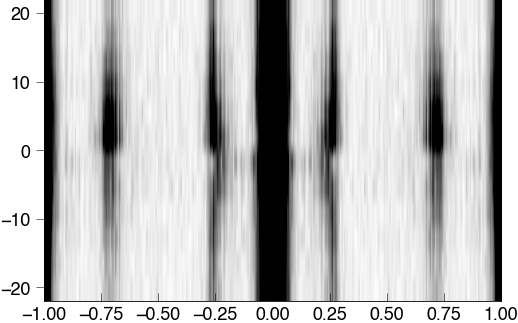

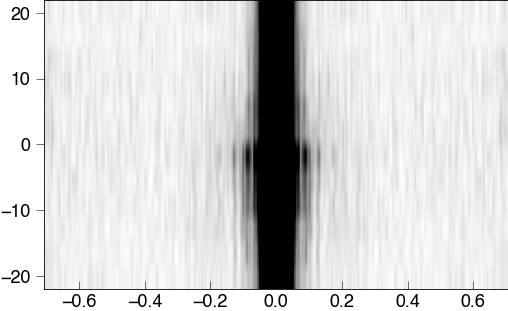

In [154]:
c = mean(cut3)
s = std(cut3)
figure(figsize=[6,4])
imshow(cut3, interpolation=None, clim=[0, c+1e-2*s], cmap=stmpy.cm.gray_r,
       extent=[-1, 1, to_plot.en[-1]*1e3, to_plot.en[0]*1e3])
gca().set_aspect(3e-2)

c = mean(cut4)
s = std(cut4)
figure(figsize=[6,4])
imshow(cut4, interpolation=None, clim=[0, c+1e-2*s], cmap=stmpy.cm.gray_r,
       extent=[-1/sqrt(2), 1/sqrt(2), to_plot.en[-1]*1e3, to_plot.en[0]*1e3])
gca().set_aspect(2e-2)

## Compare the drift corrected QPI

## Compare the 4-fold symmetrized QPI